In [ ]:
from datasets.Harmonized_Datasets import harmonize
import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy.stats import fisher_exact

In [23]:
# HELPER FUNCS

def make_table(x, y):
    n_bins_x = np.max(x) + 1
    n_bins_y = np.max(y) + 1
    tab = np.bincount(
        n_bins_y * x + y, minlength=n_bins_x * n_bins_y
    ).reshape((n_bins_x, n_bins_y))
    return tab
    

#### Goal: discover mutations associated with (predicted) sensitivity

In [4]:
mutation_matrix = pd.read_csv("../../data/Moffitt/Whole_Exome/mutation_matrix.csv")

In [5]:
mutation_matrix = mutation_matrix.set_index("Samples")

In [6]:
mutation_matrix

,CRYBG2_Missense_Mutation_p.E1154K,SPOCD1_Missense_Mutation_p.R182W,NRAS_Missense_Mutation_p.Q61H,ANKRD34A_Missense_Mutation_p.L428F,FASLG_In_Frame_Del_p.P49del,CD46_Missense_Mutation_p.P193S,ACBD3_Missense_Mutation_p.P372T,OR2L5_Missense_Mutation_p.E195A,ALLC_Missense_Mutation_p.A114S,XDH_Missense_Mutation_p.R1280C,...,DBF4B_Missense_Mutation_p.V137A,BRD4_Missense_Mutation_p.E4K,NCAN_Missense_Mutation_p.A176S,PSG1_Missense_Mutation_p.S389R,TEX101_Missense_Mutation_p.T65P,SSTR4_Missense_Mutation_p.A121V,RIPOR3_Missense_Mutation_p.T789N,PTCHD1_Missense_Mutation_p.A544S,RENBP_Nonsense_Mutation_p.C312*,UTY_Missense_Mutation_p.P1190Q
Samples,,,,,,,,,,,,,,,,,,,,,
SL429256,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
SL215362,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
SL399820,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
SL216903,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
SL239782,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SL238111,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
SL215360,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
SL399823,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [7]:
mf_ad = harmonize()['Moffitt']
ml_results_df = pd.read_csv("../../outputs/predictions_for_wes_analysis.csv").set_index("wes_id")
#maf = pd.read_csv("../../data/Moffitt/Whole_Exome/MAF.maf", sep='\t').set_index('sampleID')

/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


DeCampos Annotated data found!
Number of Harmonized Genes: 18676


In [83]:
observations_df = pd.DataFrame(mf_ad.obs.copy())

In [86]:
observations_df = observations_df.set_index("WES_SampleID")

In [ ]:
mutation_matrix_index  = list( set(ml_results_df.index) & set(mutation_matrix.index) )
mutation_columns = mutation_matrix.columns

In [87]:
mutation_matrix = mutation_matrix.loc[mutation_matrix_index]
ml_results_df = ml_results_df.loc[mutation_matrix_index]
observations_df = observations_df.loc[mutation_matrix_index]


In [90]:
mutation_matrix['y_true'] = ml_results_df['y_true']
mutation_matrix['y_pred'] = ml_results_df['y_pred']
mutation_matrix['t11_14'] = observations_df['t11_14']

/tmp/ipykernel_239292/2923073204.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  mutation_matrix['t11_14'] = observations_df['t11_14']


In [46]:


true_response_results = {}
pred_response_results = {}
count = 0
for col in mutation_columns:
    
   # if mutation_matrix[col].nunique() > 1:

        # true phenotype
        if mutation_matrix[col].nunique() > 1:
            table = make_table(mutation_matrix['y_true'].to_numpy(dtype=int), mutation_matrix[col].to_numpy(dtype=int))
            if table.shape == (2,2):
                res = fisher_exact(table, alternative='two-sided')
                true_response_results[col] = {'p': res.pvalue, 'stat': res.statistic}

            # predicted phenotype
            table = make_table(mutation_matrix['y_pred'].to_numpy(dtype=int), mutation_matrix[col].to_numpy(dtype=int))
            if table.shape == (2,2):
                
                res = fisher_exact(table, alternative='two-sided')
                pred_response_results[col] = {'p': res.pvalue, 'stat': res.statistic}
        

In [52]:
pred_results_df = pd.DataFrame(pred_response_results).T
true_results_df = pd.DataFrame(true_response_results).T

In [53]:
results_df[results_df['p'] < 0.05]

,p,stat
TMEM196_Frame_Shift_Del_p.K64fs,0.016981,inf
TAF1L_Frame_Shift_Del_p.K665fs,0.004122,inf


In [56]:
tmem = 'TMEM196_Frame_Shift_Del_p.K64fs'
taf1l = 'TAF1L_Frame_Shift_Del_p.K665fs'
pd.crosstab(mutation_matrix['y_true'], mutation_matrix[tmem])


TMEM196_Frame_Shift_Del_p.K64fs,0,1
y_true,,
0,64,1
1,39,2


In [57]:
pd.crosstab(mutation_matrix['y_true'], mutation_matrix[taf1l])


TAF1L_Frame_Shift_Del_p.K665fs,0,1
y_true,,
0,65,0
1,37,4


In [58]:
pd.crosstab(mutation_matrix['y_pred'], mutation_matrix[tmem])


TMEM196_Frame_Shift_Del_p.K64fs,0,1
y_pred,,
0,78,0
1,25,3


In [59]:
pd.crosstab(mutation_matrix['y_pred'], mutation_matrix[taf1l])


TAF1L_Frame_Shift_Del_p.K665fs,0,1
y_pred,,
0,78,0
1,24,4


In [74]:
import umap 
import scipy

reducer = umap.UMAP()
embedding = reducer.fit_transform(scipy.sparse.lil_matrix(mutation_matrix[mutation_columns]), metric='cosine')

In [92]:
embedding_df = pd.DataFrame(embedding, index=mutation_matrix.index)
embedding_df['y_true'] = mutation_matrix['y_true']
embedding_df['y_pred'] = mutation_matrix['y_pred']
embedding_df['t11_14'] = mutation_matrix['t11_14']

In [76]:
embedding_df

,0,1,y_true,y_pred
Samples,,,,
SL434801,3.699361,9.356007,1,1
SL434807,3.832328,9.497374,0,0
SL393226,3.137692,8.923605,0,0
SL374461,4.313466,7.959829,0,0
SL434810,3.520108,8.377388,0,0
...,...,...,...,...
SL429266,5.748383,10.011526,0,0
SL241598,4.307989,10.855444,0,0
SL374452,3.135517,10.737820,0,0


<Axes: xlabel='0', ylabel='1'>

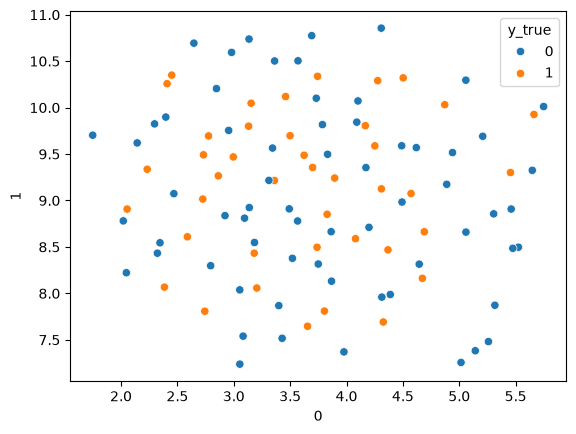

In [77]:
import seaborn as sns

sns.scatterplot(embedding_df, x=0, y=1, hue='y_true')

<Axes: xlabel='0', ylabel='1'>

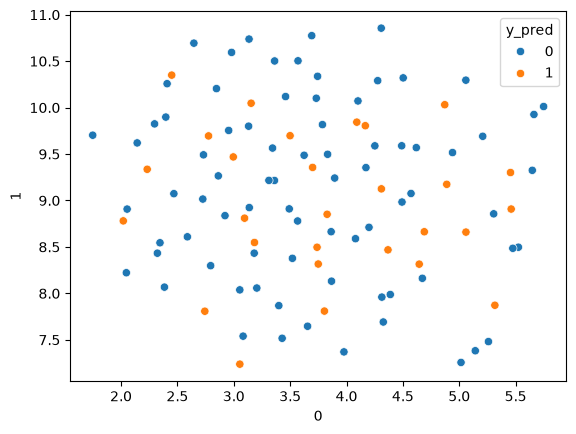

In [78]:
sns.scatterplot(embedding_df, x=0, y=1, hue='y_pred')

<Axes: xlabel='0', ylabel='1'>

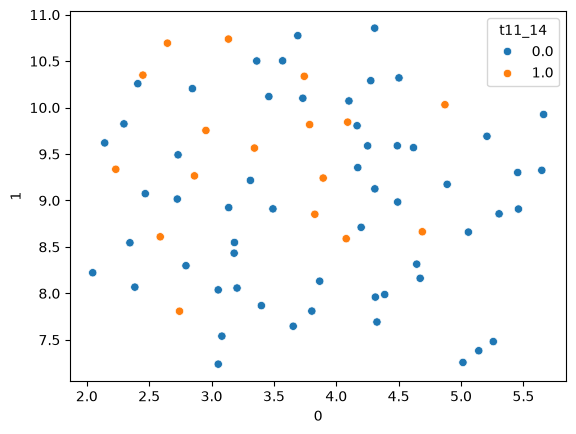

In [93]:
sns.scatterplot(embedding_df, x=0, y=1, hue='t11_14')

In [ ]:
# use logistic regression to determine if a mutation is associated with (predicted/true) phenotype when controlling for t11;14
# logistic regression with all mutations + t11;14
mutations_and_t11_14 = list(mutation_columns).copy()
mutations_and_t11_14.append('t11_14')

coefs_1 = sm.add_constant(np.column_stack(
    [mutation_matrix[col] for col in list(mutation_columns)])

)

coefs_2 = sm.add_constant(np.column_stack(
    [mutation_matrix[col] for col in mutations_and_t11_14])

)


model_1 = sm.Logit(mutation_matrix['y_true'], coefs_1).fit()

#model_2 = sm.Logit(mutation_matrix[mutation_matrix['t11_14'].notna()]['y_true'], coefs_2)



MemoryError: Unable to allocate 49.0 GiB for an array with shape (81121, 81121) and data type float64

In [ ]:
model_1.summary()

AttributeError: 'Logit' object has no attribute 'summary'